# Assignment 1B – LDA on Iris Dataset

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [64]:
df = pd.read_csv('Iris.csv')
print(df.shape)
df.head(3)

(150, 5)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa


In [65]:
feature_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = df[feature_cols]
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [66]:
# LDA – fit and transform to 2 components for visualisation
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)

print('Explained variance ratio:', lda.explained_variance_ratio_)

Explained variance ratio: [0.99147248 0.00852752]


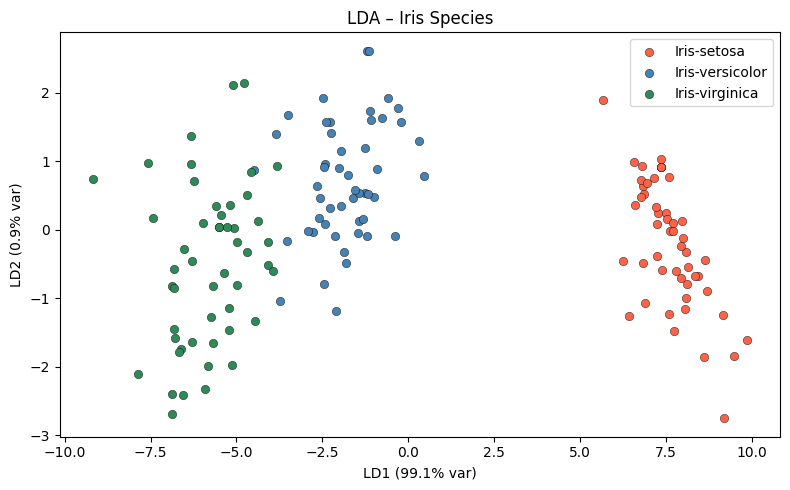

In [67]:
# Visualise LDA projection
colours = ['tomato', 'steelblue', 'seagreen']

plt.figure(figsize=(8, 5))
for cls, col in zip(df['Species'].unique(), colours):
    mask = y == cls
    plt.scatter(X_lda[mask, 0], X_lda[mask, 1],
                label=cls, c=col, edgecolors='k', linewidths=0.3)

plt.xlabel(f'LD1 ({lda.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'LD2 ({lda.explained_variance_ratio_[1]:.1%} var)')
plt.title('LDA – Iris Species')
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
# Classification using LDA (also acts as a classifier)
lda_clf = LinearDiscriminantAnalysis()
lda_clf.fit(X_train, y_train)
y_pred = lda_clf.predict(X_test)

print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



In [69]:
test_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=X.columns)
print('Predicted flower for given input:', lda_clf.predict(test_flower)[0])

Predicted flower for given input: Iris-setosa
